## Importing the dependencies 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA



c:\Users\USER\miniconda3\envs\nlp_course_env\Lib\site-packages\sklearn\utils\_param_validation.py:14: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  from scipy.sparse import csr_matrix, issparse


### Loading the dataset 

In [3]:

df = pd.read_csv("./sample_data/Test.csv")
print(df)


          ID  Gender Ever_Married  Age Graduated     Profession  \
0     458989  Female          Yes   36       Yes       Engineer   
1     458994    Male          Yes   37       Yes     Healthcare   
2     458996  Female          Yes   69        No            NaN   
3     459000    Male          Yes   59        No      Executive   
4     459001  Female           No   19        No      Marketing   
...      ...     ...          ...  ...       ...            ...   
2622  467954    Male           No   29        No     Healthcare   
2623  467958  Female           No   35       Yes         Doctor   
2624  467960  Female           No   53       Yes  Entertainment   
2625  467961    Male          Yes   47       Yes      Executive   
2626  467968  Female           No   43       Yes     Healthcare   

      Work_Experience Spending_Score  Family_Size  Var_1  
0                 0.0            Low          1.0  Cat_6  
1                 8.0        Average          4.0  Cat_6  
2                 

In [4]:
df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1
0,458989,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6
1,458994,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6
2,458996,Female,Yes,69,No,NaN,0.0,Low,1.0,Cat_6
3,459000,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6
4,459001,Female,No,19,No,Marketing,NaN,Low,4.0,Cat_6


#### Checking for missing values

In [5]:
df.isnull().sum()

ID                   0
Gender               0
Ever_Married        50
Age                  0
Graduated           24
Profession          38
Work_Experience    269
Spending_Score       0
Family_Size        113
Var_1               32
dtype: int64

### Cleaning the data
- Numeric columns (`Work_Experience`, `Family_Size`): fill with the **median**
- Categorical columns (`Ever_Married`, `Graduated`): fill with the **mode** (most common value)

In [6]:
clean = df.copy()

for col in ["Work_Experience", "Family_Size"]:
    clean[col] = clean[col].fillna(clean[col].median())


for col in ["Ever_Married", "Graduated"]:
    clean[col] = clean[col].fillna(clean[col].mode()[0])


clean[["Ever_Married", "Graduated", "Work_Experience", "Family_Size"]].isnull().sum()

Ever_Married       0
Graduated          0
Work_Experience    0
Family_Size        0
dtype: int64

### Selecting and encoding the features
KMeans works with distances between numbers, so text columns must be converted:
- `Gender`, `Ever_Married`, `Graduated` → 0/1
- `Spending_Score` → ordered 0/1/2 (Low < Average < High)

`ID` is just an identifier, and `Profession` / `Var_1` are left out to keep the segments driven by clear, ordered features (one-hot encoding many categories tends to dominate K-Means distances).

In [7]:
features = pd.DataFrame({
    "Gender": (clean["Gender"] == "Male").astype(int),
    "Ever_Married": (clean["Ever_Married"] == "Yes").astype(int),
    "Age": clean["Age"],
    "Graduated": (clean["Graduated"] == "Yes").astype(int),
    "Work_Experience": clean["Work_Experience"],
    "Spending_Score": clean["Spending_Score"].map({
        "Low": 0,
        "Average": 1,
        "High": 2
    }),
    "Family_Size": clean["Family_Size"]
})


In [8]:
features.head()

,Gender,Ever_Married,Age,Graduated,Work_Experience,Spending_Score,Family_Size
0,0,1,36,1,0.0,0,1.0
1,1,1,37,1,8.0,1,4.0
2,0,1,69,0,0.0,0,1.0
3,1,1,59,0,11.0,2,2.0
4,0,0,19,0,1.0,0,4.0


In [9]:
X = features

##### Scaling the features 

In [11]:
scaler = StandardScaler()
X_Scaled = scaler.fit_transform(X)

### Training the KMeans model

In [14]:
N_CLUSTERS = 4

model = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(X_Scaled)

df["Cluster"].value_counts().sort_index()

Cluster
0    648
1    914
2    394
3    671
Name: count, dtype: int64

### Profiling the clusters
This is where clustering becomes useful: what does each segment look like?

In [15]:
profile = X.copy()
profile["Cluster"] = df["Cluster"]
profile.groupby("Cluster").mean().round(2)

,Gender,Ever_Married,Age,Graduated,Work_Experience,Spending_Score,Family_Size
Cluster,,,,,,,
0,0.54,0.61,50.21,0.86,0.94,0.00,1.65
1,0.59,1.00,53.46,0.69,1.35,1.40,3.04
2,0.43,0.48,37.57,0.77,8.63,0.29,2.14
3,0.55,0.10,27.52,0.20,1.56,0.01,3.93


In [16]:
print(pd.crosstab(df["Cluster"], df["Spending_Score"], normalize="index").round(2))
print()
print(pd.crosstab(df["Cluster"], df["Profession"], normalize="index").round(2))

Spending_Score  Average  High   Low
Cluster                            
0                  0.00  0.00  1.00
1                  0.59  0.41  0.01
2                  0.22  0.04  0.75
3                  0.01  0.00  0.99

Profession  Artist  Doctor  Engineer  Entertainment  Executive  Healthcare  \
Cluster                                                                      
0             0.39    0.09      0.08           0.13       0.03        0.07   
1             0.38    0.07      0.09           0.12       0.15        0.02   
2             0.36    0.10      0.10           0.15       0.02        0.11   
3             0.11    0.12      0.09           0.08       0.02        0.48   

Profession  Homemaker  Lawyer  Marketing  
Cluster                                   
0                0.02    0.14       0.03  
1                0.02    0.14       0.02  
2                0.10    0.01       0.04  
3                0.02    0.00       0.08  


### Visualizing the clusters
We have 7 features, so we can't plot them on two axes like the reference did. PCA compresses them into 2 components for plotting.

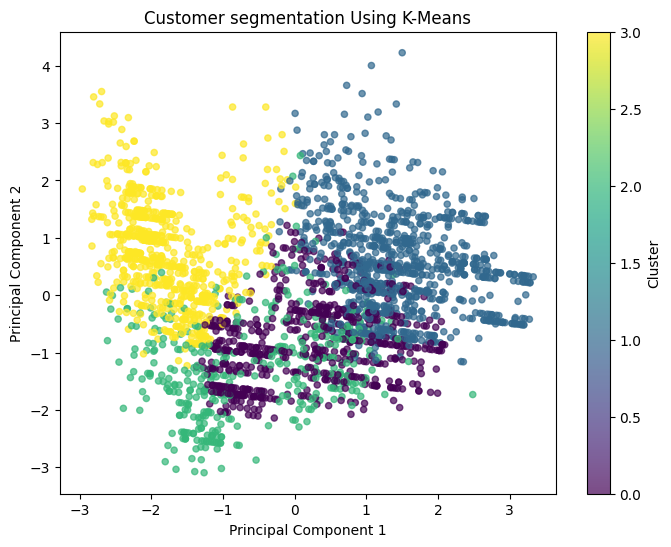

In [17]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_Scaled)

plt.figure(figsize=(8, 6))
plt.scatter(coords[:, 0], coords[:, 1], c=df["Cluster"], cmap="viridis", s=20, alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer segmentation Using K-Means")
plt.colorbar(label="Cluster")
plt.show()

In [ ]:
# df.to_csv("Test_clustered.csv", index=False)